Epoch 1/300
11/11 - 2s - 185ms/step - accuracy: 0.1441 - loss: 2.2174 - val_accuracy: 0.1667 - val_loss: 2.1701 - learning_rate: 1.0000e-03
Epoch 2/300
11/11 - 0s - 10ms/step - accuracy: 0.1882 - loss: 2.1336 - val_accuracy: 0.2333 - val_loss: 2.0945 - learning_rate: 1.0000e-03
Epoch 3/300
11/11 - 0s - 11ms/step - accuracy: 0.2353 - loss: 2.0527 - val_accuracy: 0.3833 - val_loss: 2.0148 - learning_rate: 1.0000e-03
Epoch 4/300
11/11 - 0s - 11ms/step - accuracy: 0.3324 - loss: 1.9589 - val_accuracy: 0.3833 - val_loss: 1.9245 - learning_rate: 1.0000e-03
Epoch 5/300
11/11 - 0s - 11ms/step - accuracy: 0.3559 - loss: 1.8553 - val_accuracy: 0.3667 - val_loss: 1.8294 - learning_rate: 1.0000e-03
Epoch 6/300
11/11 - 0s - 12ms/step - accuracy: 0.3941 - loss: 1.7510 - val_accuracy: 0.3833 - val_loss: 1.7341 - learning_rate: 1.0000e-03
Epoch 7/300
11/11 - 0s - 11ms/step - accuracy: 0.4029 - loss: 1.6430 - val_accuracy: 0.3667 - val_loss: 1.6391 - learning_rate: 1.0000e-03
Epoch 8/300
11/11 - 0s - 1

Synthetic Noisy Test Accuracy: 97.00%


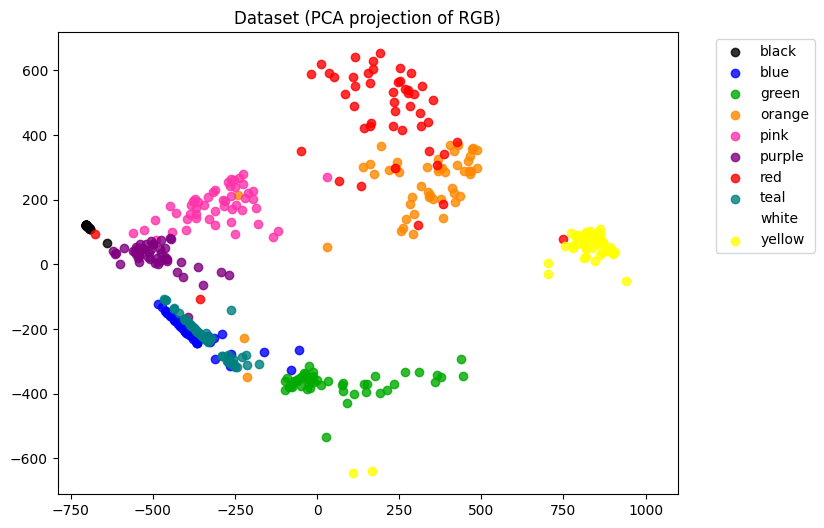

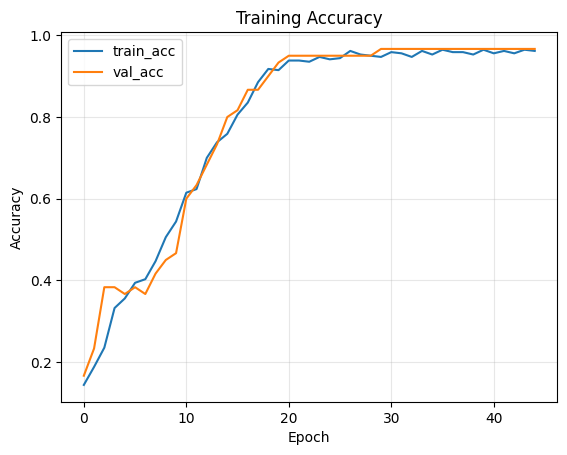

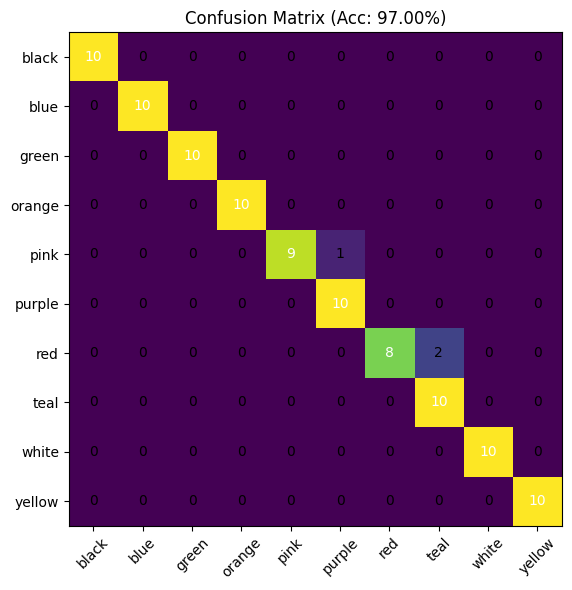


Classification Report:
              precision    recall  f1-score   support

       black     1.0000    1.0000    1.0000        10
        blue     1.0000    1.0000    1.0000        10
       green     1.0000    1.0000    1.0000        10
      orange     1.0000    1.0000    1.0000        10
        pink     1.0000    0.9000    0.9474        10
      purple     0.9091    1.0000    0.9524        10
         red     1.0000    0.8000    0.8889        10
        teal     0.8333    1.0000    0.9091        10
       white     1.0000    1.0000    1.0000        10
      yellow     1.0000    1.0000    1.0000        10

    accuracy                         0.9700       100
   macro avg     0.9742    0.9700    0.9698       100
weighted avg     0.9742    0.9700    0.9698       100


All files saved in /content/:
 - color_dnn_model_linear_trained.h5
 - color_scaler_trained.pkl
 - color_label_encoder_trained.pkl
 - color_test_predictions_report.csv
 - dataset_pca.png, train_accuracy.png, confusion

In [ ]:
# ============================================================
# Color Classifier Training (Colab version)
# Generates synthetic test samples & saves all outputs
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import joblib
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

# ==== Setup paths for Colab ====
BASE_DIR = "/content"
DATA_PATH = os.path.join(BASE_DIR, "color_dataset.csv")
MODEL_OUT = os.path.join(BASE_DIR, "ChromaCore_new.h5")
SCALER_OUT = os.path.join(BASE_DIR, "ChromaCore_scaler_new.pkl")
LABEL_ENCODER_OUT = os.path.join(BASE_DIR, "ChromaCore_label_encoder_new.pkl")
PRED_REPORT = os.path.join(BASE_DIR, "color_test_predictions_report.csv")

# ==== Load Dataset ====
df = pd.read_csv(DATA_PATH)
df.columns = [c.strip().lower() for c in df.columns]

rgb_cols = [c for c in ['r', 'g', 'b', 'red', 'green', 'blue'] if c in df.columns][:3]
label_col = [c for c in ['label', 'color', 'class'] if c in df.columns][0]

X = df[rgb_cols].astype(float).values
y_raw = df[label_col].astype(str).str.lower().str.strip().values

label_order = ['black','blue','green','orange','pink','purple','red','teal','white','yellow']
le = LabelEncoder()
le.fit(label_order)
y = le.transform(y_raw)
num_classes = len(le.classes_)
y_ohe = keras.utils.to_categorical(y, num_classes=num_classes)

# ==== Train / Test Split ====
X_train, X_test, y_train, y_test, y_train_raw, y_test_raw = train_test_split(
    X, y_ohe, y_raw, test_size=0.2, stratify=y, random_state=42
)

# ==== Scaling ====
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# ==== Generate Synthetic Test Samples (Gaussian noise) ====
# We'll add ±5% random noise to RGB values for more diverse test data
def generate_synthetic_samples(X, y_raw, factor=3):
    X_syn = []
    y_syn = []
    for i in range(len(X)):
        for _ in range(factor):
            noise = np.random.normal(0, 0.05, X.shape[1])  # 5% noise
            new_sample = X[i] * (1 + noise)
            new_sample = np.clip(new_sample, 0, 4095)  # for 12-bit ADC range
            X_syn.append(new_sample)
            y_syn.append(y_raw[i])
    return np.array(X_syn), np.array(y_syn)

X_syn, y_syn = generate_synthetic_samples(X_test, y_test_raw, factor=4)
X_syn_s = scaler.transform(X_syn)
y_syn_ohe = keras.utils.to_categorical(le.transform(y_syn), num_classes=num_classes)

# ==== Build Slightly Improved Model ====
def build_model(input_shape=(3,), num_classes=10):
    inp = layers.Input(shape=input_shape, name='rgb_in')
    x = layers.Dense(48, activation='relu', kernel_regularizer=regularizers.l2(1e-5))(inp)
    x = layers.Dropout(0.1)(x)
    x = layers.Dense(24, activation='relu', kernel_regularizer=regularizers.l2(1e-5))(x)
    out = layers.Dense(num_classes, activation='linear', name='logits')(x)
    return keras.Model(inp, out)

model = build_model(input_shape=(3,), num_classes=num_classes)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.CategoricalCrossentropy(from_logits=True),
    metrics=[keras.metrics.CategoricalAccuracy(name='accuracy')]
)

es = callbacks.EarlyStopping(monitor='val_accuracy', patience=15, restore_best_weights=True)
rlr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-6)

history = model.fit(
    X_train_s, y_train,
    validation_split=0.15,
    epochs=300,
    batch_size=32,
    callbacks=[es, rlr],
    verbose=2
)

# ==== Evaluate ====
logits_test = model.predict(X_test_s)
preds = np.argmax(logits_test, axis=1)
y_true = np.argmax(y_test, axis=1)
acc = accuracy_score(y_true, preds)
print(f"\nOriginal Test Accuracy: {acc*100:.2f}%")

# Evaluate on synthetic noisy test samples
logits_syn = model.predict(X_syn_s)
preds_syn = np.argmax(logits_syn, axis=1)
y_true_syn = np.argmax(y_syn_ohe, axis=1)
acc_syn = accuracy_score(y_true_syn, preds_syn)
print(f"Synthetic Noisy Test Accuracy: {acc_syn*100:.2f}%")

# ==== Save model and assets ====
model.save(MODEL_OUT, include_optimizer=False)
joblib.dump(scaler, SCALER_OUT)
joblib.dump(le, LABEL_ENCODER_OUT)

# ==== Visualizations ====
color_map = {
    'black': '#000000','blue': '#0000FF','green': '#00AA00','orange': '#FF8800',
    'pink': '#FF33AA','purple': '#800080','red': '#FF0000','teal': '#008080',
    'white': '#FFFFFF','yellow': '#FFFF00'
}

# 1. Dataset PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
plt.figure(figsize=(8,6))
for lab in le.classes_:
    mask = (y_raw == lab)
    plt.scatter(X_pca[mask,0], X_pca[mask,1], label=lab, color=color_map[lab], alpha=0.8)
plt.title("Dataset (PCA projection of RGB)")
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left')
plt.savefig(os.path.join(BASE_DIR, "dataset_pca.png"))
plt.show()

# 2. Accuracy curves
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.title("Training Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig(os.path.join(BASE_DIR, "train_accuracy.png"))
plt.show()

# 3. Confusion Matrix
cm = confusion_matrix(y_true, preds)
plt.figure(figsize=(8,6))
plt.imshow(cm, cmap='viridis')
plt.title(f"Confusion Matrix (Acc: {acc*100:.2f}%)")
plt.xticks(range(len(le.classes_)), le.classes_, rotation=45)
plt.yticks(range(len(le.classes_)), le.classes_)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i,j], ha='center', va='center',
                 color='white' if cm[i,j] > cm.max()/2 else 'black')
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, "confusion_matrix.png"))
plt.show()

# 4. Classification report
print("\nClassification Report:")
print(classification_report(y_true, preds, target_names=le.classes_, digits=4))

# ==== Save predictions ====
pred_probs = tf.nn.softmax(logits_test, axis=1).numpy()
report = pd.DataFrame({
    'R': X_test[:,0],'G': X_test[:,1],'B': X_test[:,2],
    'true': le.inverse_transform(y_true),
    'pred': le.inverse_transform(preds),
    'conf': pred_probs.max(axis=1)
})
report.to_csv(PRED_REPORT, index=False)

print("\nAll files saved in /content/:")
print(" - color_dnn_model_linear_trained.h5")
print(" - color_scaler_trained.pkl")
print(" - color_label_encoder_trained.pkl")
print(" - color_test_predictions_report.csv")
print(" - dataset_pca.png, train_accuracy.png, confusion_matrix.png")


In [ ]:
import joblib

scaler = joblib.load("ChromaCore_scaler_new.pkl")
print("Scaler mean:", scaler.mean_)
print("Scaler scale (std):", scaler.scale_)


Scaler mean: [415.71   566.4025 151.015 ]
Scaler scale (std): [413.73300074 406.44350837 162.54745392]
